In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


Dataset shape: (150, 5)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Number of samples in each species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


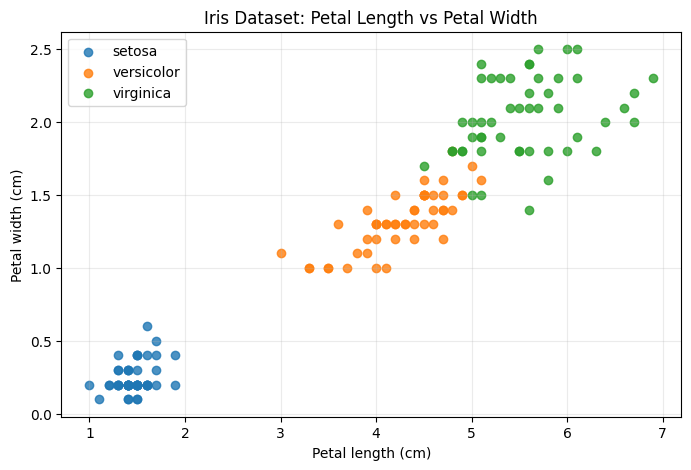

In [2]:
# Load the Iris dataset
iris = load_iris()

# Convert the data into a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = [
    iris.target_names[i] for i in iris.target
]

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nNumber of samples in each species:")
print(df["species"].value_counts())

plt.figure(figsize=(8, 5))

for species in df["species"].unique():
    subset = df[df["species"] == species]
    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=species,
        alpha=0.8
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris Dataset: Petal Length vs Petal Width")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [3]:
# Select the two species for the main experiment
selected_species = ["setosa", "versicolor"]

subset = df[df["species"].isin(selected_species)].copy()

# Select two input features
feature_names = [
    "petal length (cm)",
    "petal width (cm)"
]

X = subset[feature_names].to_numpy()

# Setosa = -1, Versicolor = +1
y = np.where(
    subset["species"].to_numpy() == "versicolor",
    1,
    -1
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", feature_names)
print("Class labels:", np.unique(y))

Training samples: 75
Testing samples: 25
Input features: ['petal length (cm)', 'petal width (cm)']
Class labels: [-1  1]


In [4]:
class Perceptron:
    def __init__(self, learning_rate=0.01, max_epochs=100):
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        # Store training history
        self.errors_per_epoch = []
        self.updates_per_epoch = []
        self.converged = False

        for epoch in range(self.max_epochs):
            errors = 0
            updates = 0

            for xi, target in zip(X, y):
                # Calculate weighted sum
                z = np.dot(xi, self.weights) + self.bias

                # A sample is misclassified if target * z <= 0
                if target * z <= 0:
                    self.weights += (
                        self.learning_rate * target * xi
                    )
                    self.bias += self.learning_rate * target

                    errors += 1
                    updates += 1

            self.errors_per_epoch.append(errors)
            self.updates_per_epoch.append(updates)

            # Stop when all training samples are classified correctly
            if errors == 0:
                self.converged = True
                print(f"Converged at epoch {epoch + 1}")
                break

        if not self.converged:
            print(
                f"Did not reach zero training errors in "
                f"{self.max_epochs} epochs."
            )

        return self

    def decision_function(self, X):
        return np.dot(X, self.weights) + self.bias

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

In [5]:
# Scale the original features
scaler_original = StandardScaler()

X_train_original = scaler_original.fit_transform(X_train)
X_test_original = scaler_original.transform(X_test)

# Train the perceptron
model_original = Perceptron(
    learning_rate=0.01,
    max_epochs=100
)

model_original.fit(X_train_original, y_train)

# Make predictions
y_pred_original = model_original.predict(X_test_original)

# Evaluate the model
accuracy_original = accuracy_score(
    y_test, y_pred_original
)

print("\nBaseline Model Results")
print("----------------------")
print(f"Test accuracy: {accuracy_original * 100:.2f}%")
print(f"Test misclassification rate: {(1 - accuracy_original) * 100:.2f}%")
print(f"Training epochs: {len(model_original.errors_per_epoch)}")
print(f"Converged: {model_original.converged}")
print("Weights:", model_original.weights)
print("Bias:", model_original.bias)

Converged at epoch 2

Baseline Model Results
----------------------
Test accuracy: 100.00%
Test misclassification rate: 0.00%
Training epochs: 2
Converged: True
Weights: [0.00916777 0.01292444]
Bias: 0.01


In [6]:
# Step 1: Standardize the original input features
scaler_for_poly = StandardScaler()

X_train_scaled = scaler_for_poly.fit_transform(X_train)
X_test_scaled = scaler_for_poly.transform(X_test)

# Step 2: Generate polynomial features
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly_raw = poly.fit_transform(X_train_scaled)
X_test_poly_raw = poly.transform(X_test_scaled)

# Step 3: Standardize the expanded feature matrix
scaler_poly = StandardScaler()

X_train_poly = scaler_poly.fit_transform(X_train_poly_raw)
X_test_poly = scaler_poly.transform(X_test_poly_raw)

print("Original number of features:", X_train.shape[1])
print("Engineered number of features:", X_train_poly.shape[1])

print("\nEngineered feature names:")
print(poly.get_feature_names_out(feature_names))

model_poly = Perceptron(
    learning_rate=0.01,
    max_epochs=100
)

model_poly.fit(X_train_poly, y_train)

y_pred_poly = model_poly.predict(X_test_poly)

accuracy_poly = accuracy_score(
    y_test, y_pred_poly
)

print("\nPolynomial Feature Model Results")
print("--------------------------------")
print(f"Test accuracy: {accuracy_poly * 100:.2f}%")
print(f"Test misclassification rate: {(1 - accuracy_poly) * 100:.2f}%")
print(f"Training epochs: {len(model_poly.errors_per_epoch)}")
print(f"Converged: {model_poly.converged}")

Original number of features: 2
Engineered number of features: 5

Engineered feature names:
['petal length (cm)' 'petal width (cm)' 'petal length (cm)^2'
 'petal length (cm) petal width (cm)' 'petal width (cm)^2']
Converged at epoch 2

Polynomial Feature Model Results
--------------------------------
Test accuracy: 100.00%
Test misclassification rate: 0.00%
Training epochs: 2
Converged: True


In [7]:
results = pd.DataFrame({
    "Experiment": [
        "Original Features",
        "Polynomial Features"
    ],
    "Number of Features": [
        X_train_original.shape[1],
        X_train_poly.shape[1]
    ],
    "Training Epochs": [
        len(model_original.errors_per_epoch),
        len(model_poly.errors_per_epoch)
    ],
    "Converged": [
        model_original.converged,
        model_poly.converged
    ],
    "Test Accuracy (%)": [
        accuracy_original * 100,
        accuracy_poly * 100
    ],
    "Test Misclassification (%)": [
        (1 - accuracy_original) * 100,
        (1 - accuracy_poly) * 100
    ]
})

display(results.round(2))

,Experiment,Number of Features,Training Epochs,Converged,Test Accuracy (%),Test Misclassification (%)
0,Original Features,2,2,True,100.0,0.0
1,Polynomial Features,5,2,True,100.0,0.0


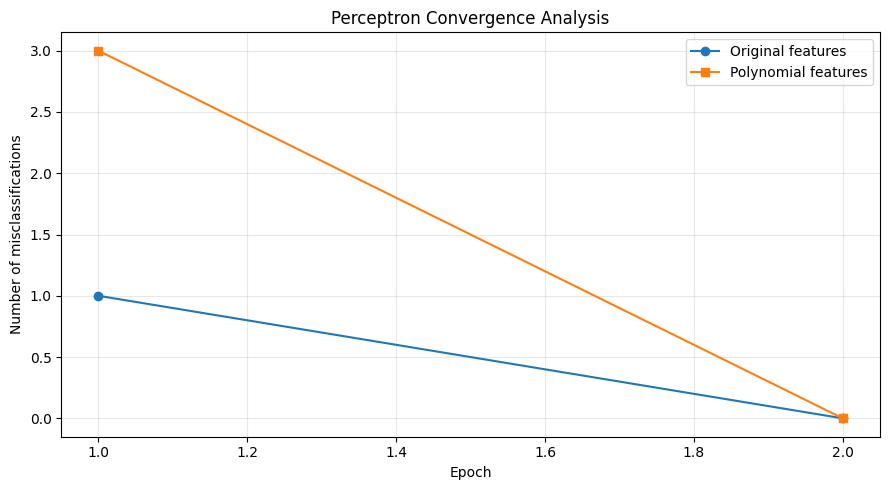

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(model_original.errors_per_epoch) + 1),
    model_original.errors_per_epoch,
    marker="o",
    label="Original features"
)

plt.plot(
    range(1, len(model_poly.errors_per_epoch) + 1),
    model_poly.errors_per_epoch,
    marker="s",
    label="Polynomial features"
)

plt.xlabel("Epoch")
plt.ylabel("Number of misclassifications")
plt.title("Perceptron Convergence Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("convergence_analysis.png", dpi=300)
plt.show()

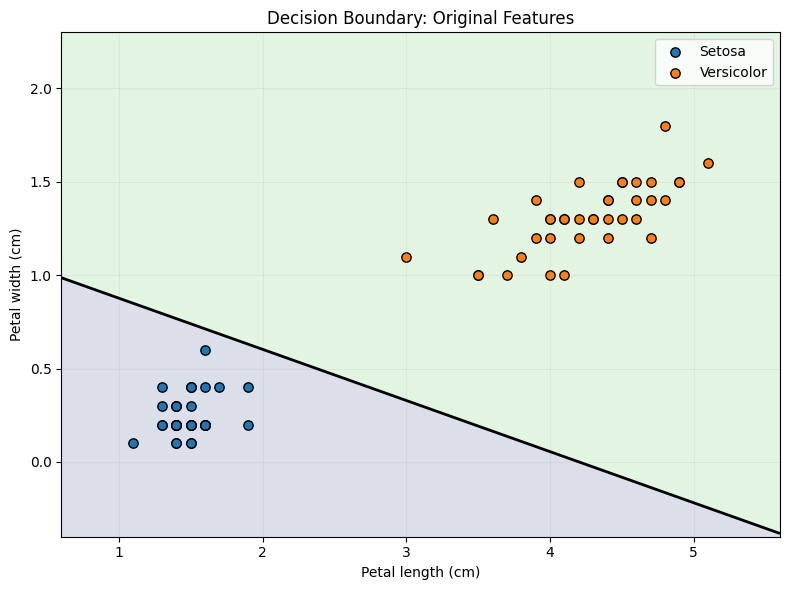

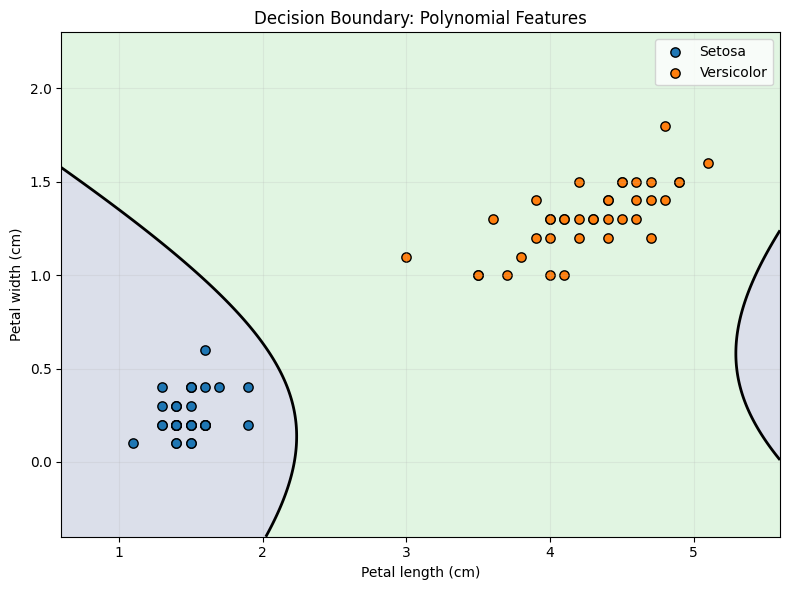

In [9]:
def plot_decision_boundary(
    X_raw,
    y_labels,
    model,
    transform_function,
    title
):
    # Create a grid in the original feature space
    x_min, x_max = X_raw[:, 0].min() - 0.5, X_raw[:, 0].max() + 0.5
    y_min, y_max = X_raw[:, 1].min() - 0.5, X_raw[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    # Convert grid points into model input features
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_transformed = transform_function(grid)

    # Calculate model scores at every grid point
    scores = model.decision_function(grid_transformed)
    scores = scores.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    # Draw the two predicted regions
    plt.contourf(
        xx, yy, scores,
        levels=[-1000, 0, 1000],
        alpha=0.18
    )

    # Draw the boundary where score = 0
    plt.contour(
        xx, yy, scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    # Plot the actual samples
    for label, name in [(-1, "Setosa"), (1, "Versicolor")]:
        mask = y_labels == label
        plt.scatter(
            X_raw[mask, 0],
            X_raw[mask, 1],
            label=name,
            edgecolors="black",
            s=45
        )

    plt.xlabel("Petal length (cm)")
    plt.ylabel("Petal width (cm)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    # Transformation for the original-feature model
def transform_original(grid):
    return scaler_original.transform(grid)

# Transformation for the polynomial-feature model
def transform_polynomial(grid):
    grid_scaled = scaler_for_poly.transform(grid)
    grid_poly = poly.transform(grid_scaled)
    return scaler_poly.transform(grid_poly)

plot_decision_boundary(
    X_train,
    y_train,
    model_original,
    transform_original,
    "Decision Boundary: Original Features"
)

plot_decision_boundary(
    X_train,
    y_train,
    model_poly,
    transform_polynomial,
    "Decision Boundary: Polynomial Features"
)

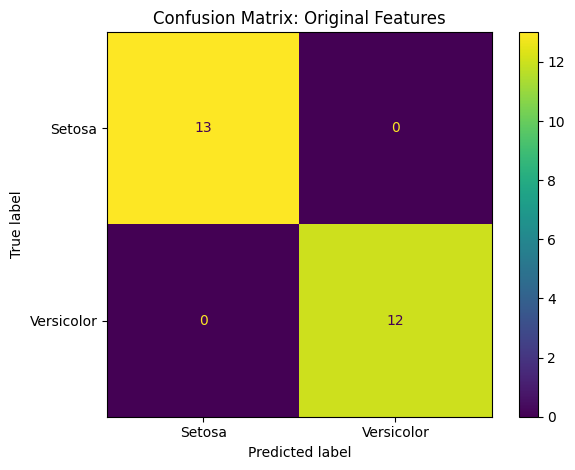


Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        13
  Versicolor       1.00      1.00      1.00        12

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_original,
    labels=[-1, 1]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Setosa", "Versicolor"]
)

display_matrix.plot()
plt.title("Confusion Matrix: Original Features")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_original,
        labels=[-1, 1],
        target_names=["Setosa", "Versicolor"],
        zero_division=0
    )
)

Did not reach zero training errors in 100 epochs.

Challenging Dataset Results
---------------------------
Test accuracy: 88.00%
Training epochs: 100
Converged: False
Final training errors: 4


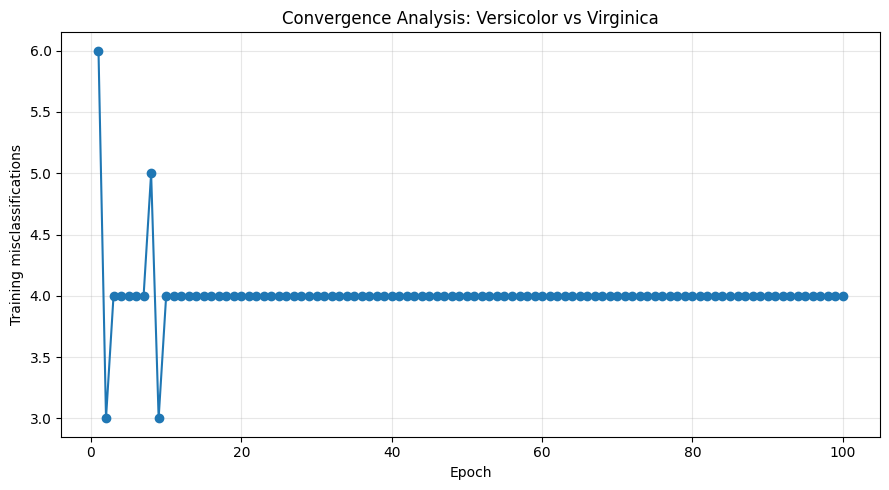

In [11]:
# Select the more challenging species pair
hard_subset = df[
    df["species"].isin(["versicolor", "virginica"])
].copy()

X_hard = hard_subset[feature_names].to_numpy()

y_hard = np.where(
    hard_subset["species"].to_numpy() == "virginica",
    1,
    -1
)

Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_hard,
    y_hard,
    test_size=0.25,
    random_state=42,
    stratify=y_hard
)

# Scale without using test data
hard_scaler = StandardScaler()
Xh_train_scaled = hard_scaler.fit_transform(Xh_train)
Xh_test_scaled = hard_scaler.transform(Xh_test)

# Train the perceptron
model_hard = Perceptron(
    learning_rate=0.01,
    max_epochs=100
)

model_hard.fit(Xh_train_scaled, yh_train)

yh_pred = model_hard.predict(Xh_test_scaled)

hard_accuracy = accuracy_score(yh_test, yh_pred)

print("\nChallenging Dataset Results")
print("---------------------------")
print(f"Test accuracy: {hard_accuracy * 100:.2f}%")
print(f"Training epochs: {len(model_hard.errors_per_epoch)}")
print(f"Converged: {model_hard.converged}")
print(
    "Final training errors:",
    model_hard.errors_per_epoch[-1]
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(model_hard.errors_per_epoch) + 1),
    model_hard.errors_per_epoch,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training misclassifications")
plt.title("Convergence Analysis: Versicolor vs Virginica")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("challenging_convergence.png", dpi=300)
plt.show()

Converged at epoch 2
Converged at epoch 2
Converged at epoch 2


,Learning Rate,Epochs,Converged,Test Accuracy (%),Final Training Errors
0,0.001,2,True,100.0,0
1,0.010,2,True,100.0,0
2,0.100,2,True,100.0,0


Converged at epoch 2
Converged at epoch 2
Converged at epoch 2


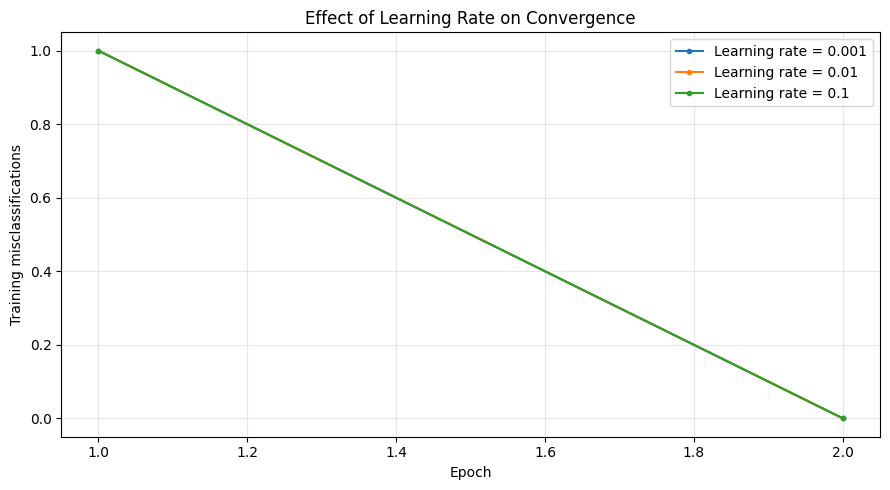

In [12]:
learning_rates = [0.001, 0.01, 0.1]
learning_rate_results = []

for lr in learning_rates:
    temp_model = Perceptron(
        learning_rate=lr,
        max_epochs=100
    )

    temp_model.fit(X_train_original, y_train)

    predictions = temp_model.predict(X_test_original)

    learning_rate_results.append({
        "Learning Rate": lr,
        "Epochs": len(temp_model.errors_per_epoch),
        "Converged": temp_model.converged,
        "Test Accuracy (%)": (
            accuracy_score(y_test, predictions) * 100
        ),
        "Final Training Errors": (
            temp_model.errors_per_epoch[-1]
        )
    })

lr_results = pd.DataFrame(learning_rate_results)
display(lr_results.round(3))
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    temp_model = Perceptron(
        learning_rate=lr,
        max_epochs=100
    )
    temp_model.fit(X_train_original, y_train)

    plt.plot(
        range(1, len(temp_model.errors_per_epoch) + 1),
        temp_model.errors_per_epoch,
        marker=".",
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training misclassifications")
plt.title("Effect of Learning Rate on Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_rate_comparison.png", dpi=300)
plt.show()

In [13]:
# Save the comparison table
results.to_csv("perceptron_experiment_results.csv", index=False)

# Save epoch-wise convergence data
convergence_df = pd.DataFrame({
    "Epoch_Original": range(
        1, len(model_original.errors_per_epoch) + 1
    ),
    "Errors_Original": pd.Series(
        model_original.errors_per_epoch
    ),
})

convergence_df.to_csv(
    "perceptron_convergence_history.csv",
    index=False
)

print("Results saved successfully!")
print("Files created:")
print("- perceptron_experiment_results.csv")
print("- perceptron_convergence_history.csv")
print("- convergence_analysis.png")
print("- confusion_matrix.png")
print("- challenging_convergence.png")
print("- learning_rate_comparison.png")

Results saved successfully!
Files created:
- perceptron_experiment_results.csv
- perceptron_convergence_history.csv
- convergence_analysis.png
- confusion_matrix.png
- challenging_convergence.png
- learning_rate_comparison.png
